In [ ]:
!pip install -q matplotlib numpy opencv-python-headless

In [ ]:
from google.colab import files
import cv2, numpy as np

print("Upload your image:")
uploaded = files.upload()
filename = list(uploaded.keys())[0]

img_bgr = cv2.imdecode(np.frombuffer(uploaded[filename], np.uint8), cv2.IMREAD_COLOR)
img_rgb = cv2.cvtColor(img_bgr, cv2.COLOR_BGR2RGB)
height, width = img_rgb.shape[:2]
print(f"Image: {width}x{height} ({width*height:,} pixels)")

Upload your image:


Saving lily_flower.jpg to lily_flower.jpg
Image: 640x960 (614,400 pixels)


Compiling...
Compiled successfully!

Running benchmark...

  Image      : 640 x 960  (614400 pixels)
  CPU Threads: 2
  Avg of 10 runs each

--- Running Sequential CPU ---
  Time  : 2.3026 ms
  Cycles: 4605235

--- Running OpenMP CPU (2 threads) ---
  Time  : 1.9192 ms
  Cycles: 3838409

--- Running CUDA GPU ---
  Time  : 0.013840 ms
  Cycles: 13840

  RESULTS SUMMARY
  Sequential CPU :   2.3026 ms   Speedup: 1.00x
  OpenMP CPU     :   1.9192 ms   Speedup: 1.20x
  CUDA GPU       : 0.013840 ms   Speedup: 166.37x




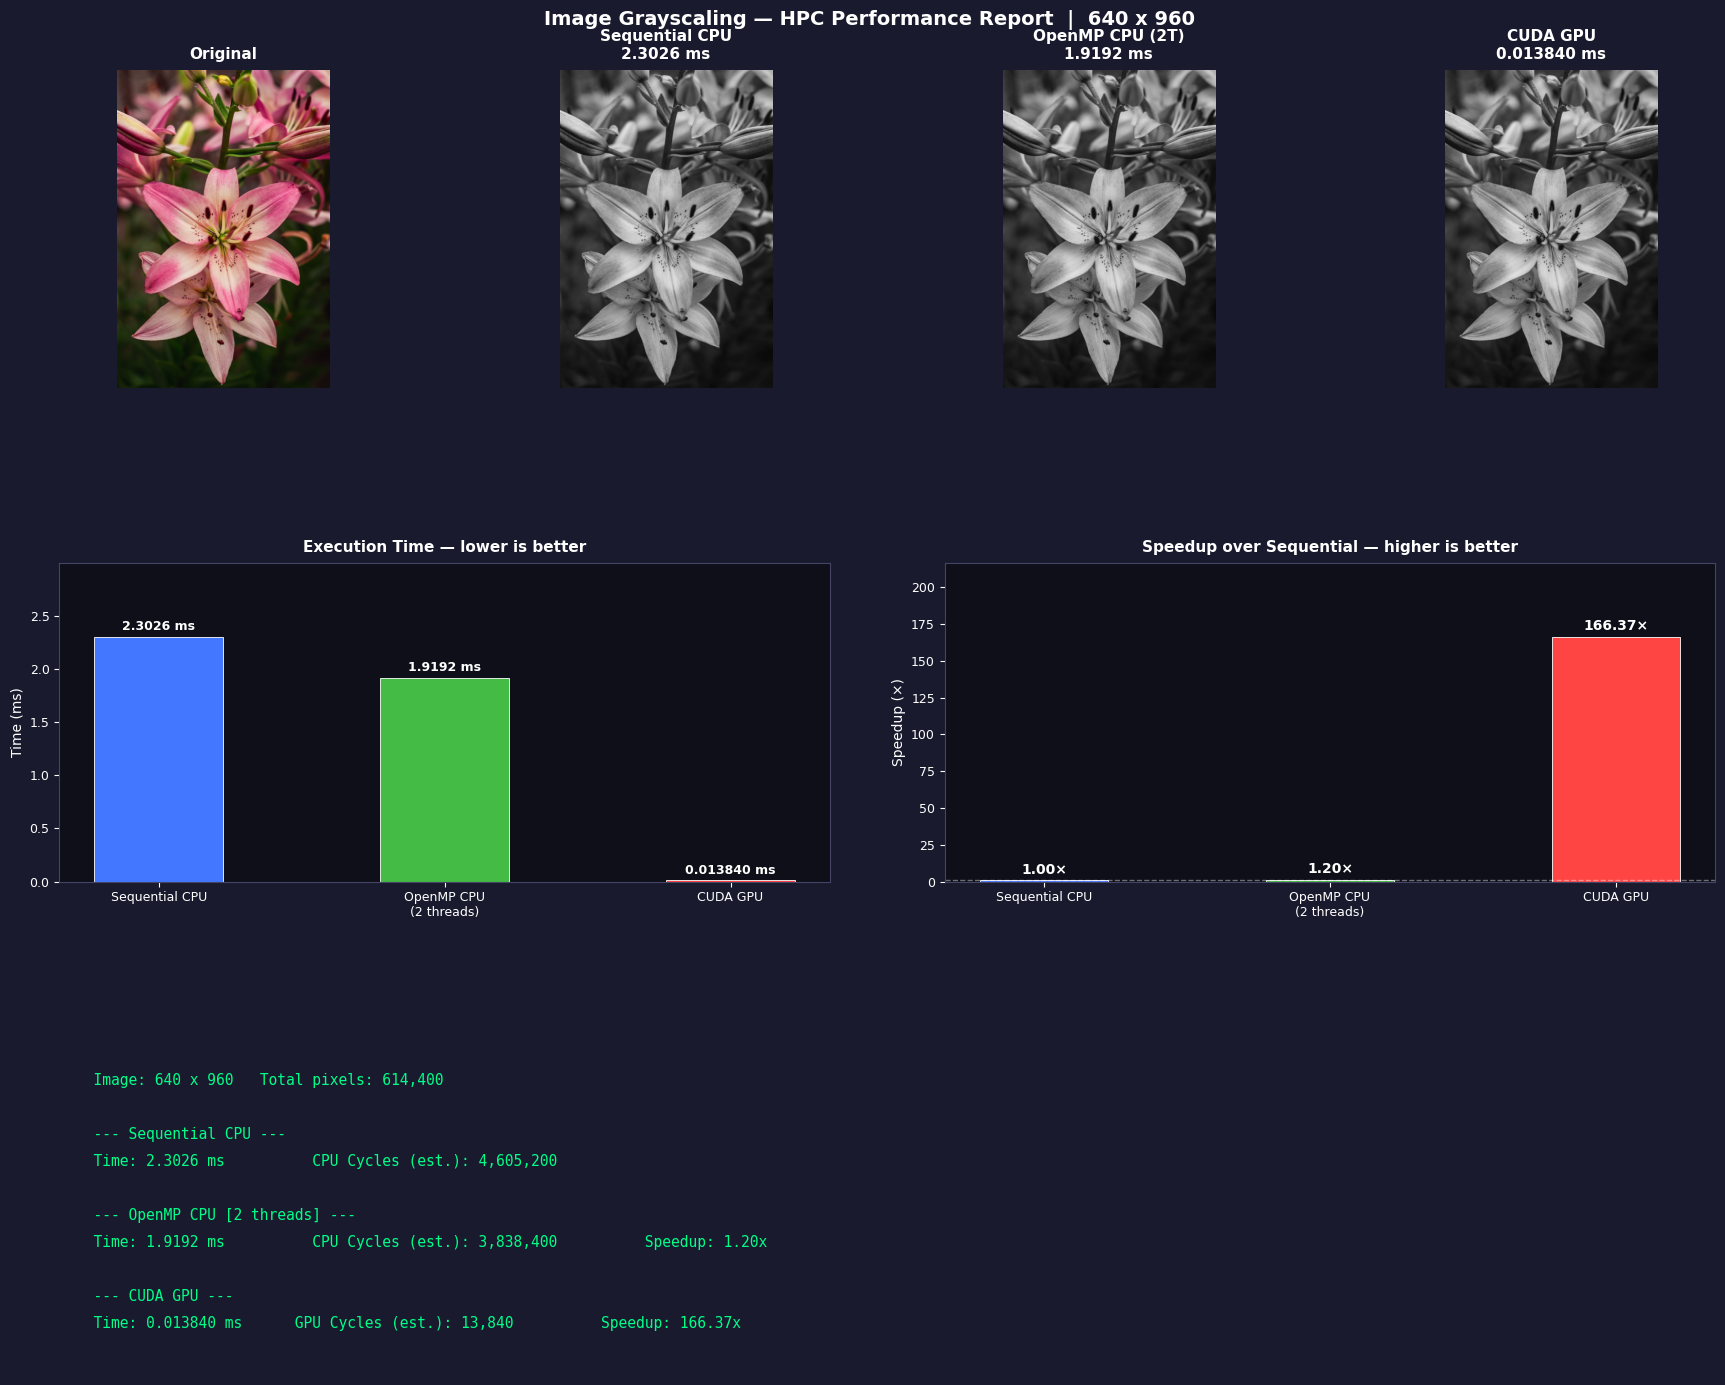

Report saved: /content/grayscale_report.png


In [ ]:
import subprocess, re, sys
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.gridspec as gridspec

# ── Embed image dimensions and pixel data into the C source ───
flat      = img_rgb.reshape(-1, 3).astype(np.uint8)
total     = width * height
hex_bytes = ", ".join(f"0x{b:02x}" for b in flat.tobytes())

cuda_src = f"""
#include <stdio.h>
#include <stdlib.h>
#include <time.h>
#include <omp.h>
#include <cuda_runtime.h>

#define WIDTH   {width}
#define HEIGHT  {height}
#define TOTAL   {total}
#define RUNS    10

// ── Pixel data embedded at compile time ──────────────────────
static const unsigned char RGB_DATA[] = {{ {hex_bytes} }};

// ─────────────────────────────────────────────────────────────
// 1. Serial CPU
// ─────────────────────────────────────────────────────────────
void grayscale_serial(const unsigned char* rgb, unsigned char* gray) {{
    for (int i = 0; i < TOTAL; i++) {{
        gray[i] = (unsigned char)(
            0.299f * rgb[i*3 + 0] +
            0.587f * rgb[i*3 + 1] +
            0.114f * rgb[i*3 + 2]
        );
    }}
}}

// ─────────────────────────────────────────────────────────────
// 2. OpenMP parallel CPU
// ─────────────────────────────────────────────────────────────
void grayscale_openmp(const unsigned char* rgb, unsigned char* gray, int nthreads) {{
    #pragma omp parallel for num_threads(nthreads) schedule(static)
    for (int i = 0; i < TOTAL; i++) {{
        gray[i] = (unsigned char)(
            0.299f * rgb[i*3 + 0] +
            0.587f * rgb[i*3 + 1] +
            0.114f * rgb[i*3 + 2]
        );
    }}
}}

// ─────────────────────────────────────────────────────────────
// 3. CUDA GPU — one thread per pixel
// ─────────────────────────────────────────────────────────────
__global__ void grayscale_kernel(const unsigned char* rgb,
                                  unsigned char* gray) {{
    int i = blockIdx.x * blockDim.x + threadIdx.x;
    if (i < TOTAL) {{
        gray[i] = (unsigned char)(
            0.299f * rgb[i*3 + 0] +
            0.587f * rgb[i*3 + 1] +
            0.114f * rgb[i*3 + 2]
        );
    }}
}}

double elapsed_ms(struct timespec t0, struct timespec t1) {{
    return (t1.tv_sec - t0.tv_sec) * 1000.0
         + (t1.tv_nsec - t0.tv_nsec) / 1e6;
}}

int main() {{
    int nthreads = omp_get_max_threads();

    printf("\\n================================================\\n");
    printf("  Image      : %d x %d  (%d pixels)\\n", WIDTH, HEIGHT, TOTAL);
    printf("  CPU Threads: %d\\n", nthreads);
    printf("  Avg of %d runs each\\n", RUNS);
    printf("================================================\\n");

    unsigned char* gray_serial = (unsigned char*)malloc(TOTAL);
    unsigned char* gray_omp    = (unsigned char*)malloc(TOTAL);
    unsigned char* gray_cuda   = (unsigned char*)malloc(TOTAL);

    struct timespec t0, t1;

    // ── Serial ────────────────────────────────────────────────
    printf("\\n--- Running Sequential CPU ---\\n");
    clock_gettime(CLOCK_MONOTONIC, &t0);
    for (int r = 0; r < RUNS; r++)
        grayscale_serial(RGB_DATA, gray_serial);
    clock_gettime(CLOCK_MONOTONIC, &t1);
    double serial_ms = elapsed_ms(t0, t1) / RUNS;
    long serial_cyc  = (long)(serial_ms * 2000000.0);
    printf("  Time  : %.4f ms\\n", serial_ms);
    printf("  Cycles: %ld\\n", serial_cyc);

    // ── OpenMP ────────────────────────────────────────────────
    printf("\\n--- Running OpenMP CPU (%d threads) ---\\n", nthreads);
    clock_gettime(CLOCK_MONOTONIC, &t0);
    for (int r = 0; r < RUNS; r++)
        grayscale_openmp(RGB_DATA, gray_omp, nthreads);
    clock_gettime(CLOCK_MONOTONIC, &t1);
    double omp_ms = elapsed_ms(t0, t1) / RUNS;
    long omp_cyc  = (long)(omp_ms * 2000000.0);
    printf("  Time  : %.4f ms\\n", omp_ms);
    printf("  Cycles: %ld\\n", omp_cyc);

    // ── CUDA ──────────────────────────────────────────────────
    printf("\\n--- Running CUDA GPU ---\\n");

    unsigned char *rgb_dev, *gray_dev;
    cudaMalloc(&rgb_dev,  TOTAL * 3);
    cudaMalloc(&gray_dev, TOTAL);
    cudaMemcpy(rgb_dev, RGB_DATA, TOTAL * 3, cudaMemcpyHostToDevice);

    int tpb    = 256;
    int blocks = (TOTAL + tpb - 1) / tpb;

    // Warm-up
    grayscale_kernel<<<blocks, tpb>>>(rgb_dev, gray_dev);
    cudaDeviceSynchronize();

    cudaEvent_t start, stop;
    cudaEventCreate(&start);
    cudaEventCreate(&stop);
    cudaEventRecord(start);
    for (int r = 0; r < RUNS; r++)
        grayscale_kernel<<<blocks, tpb>>>(rgb_dev, gray_dev);
    cudaEventRecord(stop);
    cudaEventSynchronize(stop);

    float cuda_total_ms = 0;
    cudaEventElapsedTime(&cuda_total_ms, start, stop);
    double cuda_ms = cuda_total_ms / RUNS;
    long cuda_cyc  = (long)(cuda_ms * 1000000.0);

    cudaMemcpy(gray_cuda, gray_dev, TOTAL, cudaMemcpyDeviceToHost);
    printf("  Time  : %.6f ms\\n", cuda_ms);
    printf("  Cycles: %ld\\n", cuda_cyc);

    // ── Summary ───────────────────────────────────────────────
    double spd_omp  = serial_ms / omp_ms;
    double spd_cuda = serial_ms / cuda_ms;

    printf("\\n================================================\\n");
    printf("  RESULTS SUMMARY\\n");
    printf("================================================\\n");
    printf("  Sequential CPU : %8.4f ms   Speedup: 1.00x\\n", serial_ms);
    printf("  OpenMP CPU     : %8.4f ms   Speedup: %.2fx\\n", omp_ms,  spd_omp);
    printf("  CUDA GPU       : %8.6f ms   Speedup: %.2fx\\n", cuda_ms, spd_cuda);
    printf("================================================\\n");

    // ── Print pixel arrays for Python to read back ────────────
    // Serial grayscale
    printf("\\nBEGIN_SERIAL\\n");
    for (int i = 0; i < TOTAL; i++) printf("%d\\n", gray_serial[i]);
    printf("END_SERIAL\\n");

    // OpenMP grayscale
    printf("\\nBEGIN_OMP\\n");
    for (int i = 0; i < TOTAL; i++) printf("%d\\n", gray_omp[i]);
    printf("END_OMP\\n");

    // CUDA grayscale
    printf("\\nBEGIN_CUDA\\n");
    for (int i = 0; i < TOTAL; i++) printf("%d\\n", gray_cuda[i]);
    printf("END_CUDA\\n");

    free(gray_serial); free(gray_omp); free(gray_cuda);
    cudaFree(rgb_dev); cudaFree(gray_dev);
    cudaEventDestroy(start); cudaEventDestroy(stop);
    return 0;
}}
"""

# ── Write source ──────────────────────────────────────────────
with open("/content/grayscale.cu", "w") as f:
    f.write(cuda_src)

# ── Compile ───────────────────────────────────────────────────
print("Compiling...")
comp = subprocess.run(
    ["nvcc", "-O2", "-Xcompiler", "-fopenmp",
     "/content/grayscale.cu", "-o", "/content/grayscale", "-lm"],
    capture_output=True, text=True
)
if comp.returncode != 0:
    print("COMPILE ERROR:\n", comp.stderr)
    sys.exit()
print("Compiled successfully!\n")

# ── Run ───────────────────────────────────────────────────────
print("Running benchmark...")
run = subprocess.run(["/content/grayscale"], capture_output=True, text=True)
out = run.stdout
print(out[:out.find("BEGIN_SERIAL")])   # print summary only

# ── Parse timings ─────────────────────────────────────────────
serial_ms = float(re.search(r"Sequential CPU\s*:\s*([\d.]+)", out).group(1))
omp_ms    = float(re.search(r"OpenMP CPU\s*:\s*([\d.]+)",     out).group(1))
cuda_ms   = float(re.search(r"CUDA GPU\s*:\s*([\d.]+)",       out).group(1))
spd_omp   = float(re.search(r"OpenMP CPU.*Speedup:\s*([\d.]+)",   out).group(1))
spd_cuda  = float(re.search(r"CUDA GPU.*Speedup:\s*([\d.]+)",     out).group(1))

serial_cyc = int(serial_ms * 2_000_000)
omp_cyc    = int(omp_ms    * 2_000_000)
cuda_cyc   = int(cuda_ms   * 1_000_000)

# ── Parse pixel arrays ────────────────────────────────────────
def extract_pixels(tag, text, total, h, w):
    m = re.search(rf"BEGIN_{tag}\n(.*?)\nEND_{tag}", text, re.DOTALL)
    arr = np.array(m.group(1).strip().split("\n"), dtype=np.uint8)
    return arr.reshape(h, w)

gray_serial_img = extract_pixels("SERIAL", out, total, height, width)
gray_omp_img    = extract_pixels("OMP",    out, total, height, width)
gray_cuda_img   = extract_pixels("CUDA",   out, total, height, width)

import multiprocessing
nthreads = multiprocessing.cpu_count()

# ── Plot ──────────────────────────────────────────────────────
fig = plt.figure(figsize=(18, 15))
fig.patch.set_facecolor("#1a1a2e")

gs = gridspec.GridSpec(3, 4, figure=fig,
                       hspace=0.55, wspace=0.35,
                       left=0.05, right=0.97,
                       top=0.93, bottom=0.06)

title_kw = dict(fontsize=11, color="white", fontweight="bold", pad=8)
ax_bg    = "#0f0f1a"

def style_ax(ax, title):
    ax.set_facecolor(ax_bg)
    ax.set_title(title, **title_kw)
    ax.tick_params(colors="white", labelsize=9)
    for sp in ax.spines.values():
        sp.set_edgecolor("#444466")

# Row 1: images
for col, (data, cmap, label) in enumerate([
    (img_rgb,        None,   "Original"),
    (gray_serial_img,"gray", f"Sequential CPU\n{serial_ms:.4f} ms"),
    (gray_omp_img,   "gray", f"OpenMP CPU ({nthreads}T)\n{omp_ms:.4f} ms"),
    (gray_cuda_img,  "gray", f"CUDA GPU\n{cuda_ms:.6f} ms"),
]):
    ax = fig.add_subplot(gs[0, col])
    ax.axis("off")
    ax.set_facecolor(ax_bg)
    kw = {"cmap": cmap, "vmin": 0, "vmax": 255} if cmap else {}
    ax.imshow(data, **kw)
    ax.set_title(label, **title_kw)

# Row 2 left: execution time
ax_time = fig.add_subplot(gs[1, :2])
methods = ["Sequential CPU", f"OpenMP CPU\n({nthreads} threads)", "CUDA GPU"]
times   = [serial_ms, omp_ms, cuda_ms]
colors  = ["#4477ff", "#44bb44", "#ff4444"]

bars = ax_time.bar(methods, times, color=colors, width=0.45, edgecolor="white", linewidth=0.6)
style_ax(ax_time, "Execution Time — lower is better")
ax_time.set_ylabel("Time (ms)", color="white", fontsize=10)
ax_time.yaxis.label.set_color("white")
for bar, t in zip(bars, times):
    lbl = f"{t:.6f} ms" if t < 0.1 else f"{t:.4f} ms"
    ax_time.text(bar.get_x() + bar.get_width()/2,
                 bar.get_height() + max(times)*0.015,
                 lbl, ha="center", va="bottom",
                 color="white", fontsize=9, fontweight="bold")
ax_time.set_ylim(0, max(times) * 1.3)

# Row 2 right: speedup
ax_spd   = fig.add_subplot(gs[1, 2:])
speedups = [1.0, spd_omp, spd_cuda]

bars2 = ax_spd.bar(methods, speedups, color=colors, width=0.45, edgecolor="white", linewidth=0.6)
ax_spd.axhline(y=1, color="white", linestyle="--", linewidth=1, alpha=0.4)
style_ax(ax_spd, "Speedup over Sequential — higher is better")
ax_spd.set_ylabel("Speedup (×)", color="white", fontsize=10)
ax_spd.yaxis.label.set_color("white")
for bar, s in zip(bars2, speedups):
    ax_spd.text(bar.get_x() + bar.get_width()/2,
                bar.get_height() + max(speedups)*0.015,
                f"{s:.2f}×", ha="center", va="bottom",
                color="white", fontsize=10, fontweight="bold")
ax_spd.set_ylim(0, max(speedups) * 1.3)

# Row 3: terminal metrics panel
ax_m = fig.add_subplot(gs[2, :])
ax_m.set_facecolor("#0d0d1f")
ax_m.axis("off")
for sp in ax_m.spines.values():
    sp.set_edgecolor("#00ff88")

metrics = (
    f"  Image: {width} x {height}   Total pixels: {total:,}\n\n"
    f"  --- Sequential CPU ---\n"
    f"  Time: {serial_ms:.4f} ms          CPU Cycles (est.): {serial_cyc:,}\n\n"
    f"  --- OpenMP CPU [{nthreads} threads] ---\n"
    f"  Time: {omp_ms:.4f} ms          CPU Cycles (est.): {omp_cyc:,}          "
    f"Speedup: {spd_omp:.2f}x\n\n"
    f"  --- CUDA GPU ---\n"
    f"  Time: {cuda_ms:.6f} ms      GPU Cycles (est.): {cuda_cyc:,}          "
    f"Speedup: {spd_cuda:.2f}x"
)

ax_m.text(0.01, 0.95, metrics,
          transform=ax_m.transAxes,
          fontsize=10.5, color="#00ff88",
          fontfamily="monospace",
          verticalalignment="top",
          linespacing=2.0)

fig.suptitle(
    f"Image Grayscaling — HPC Performance Report  |  {width} x {height}",
    fontsize=14, color="white", fontweight="bold", y=0.97
)

plt.savefig("/content/grayscale_report.png", dpi=150,
            bbox_inches="tight", facecolor=fig.get_facecolor())
plt.show()
print("Report saved: /content/grayscale_report.png")